In [1]:
!pip -q install elevation rasterio shapely geopandas

In [2]:
import os
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path

In [3]:
DATA_DIR = Path("data")
SRTM_DIR = DATA_DIR / "srtm"
TERRAIN_DIR = DATA_DIR / "terrain"

SRTM_DIR.mkdir(parents=True, exist_ok=True)
TERRAIN_DIR.mkdir(parents=True, exist_ok=True)

print("SRTM directory:", SRTM_DIR)
print("Terrain directory:", TERRAIN_DIR)

SRTM directory: data\srtm
Terrain directory: data\terrain


In [4]:
test_lat = 22.3039
test_lon = 70.8022

print("Latitude:", test_lat)
print("Longitude:", test_lon)

Latitude: 22.3039
Longitude: 70.8022


In [5]:
import elevation

test_dem = SRTM_DIR / "test_dem_inland.tif"

elevation.clip(
    bounds=(
        test_lon - 0.05,
        test_lat - 0.05,
        test_lon + 0.05,
        test_lat + 0.05
    ),
    output=str(test_dem)
)

print("DEM created:", test_dem.exists())
print("File:", test_dem)

CalledProcessError: Command 'make -C C:\Users\nalla\AppData\Local\bopen\elevation\Cache\SRTM1 download ENSURE_TILES="N22/N22E070.tif"' returned non-zero exit status 1.

In [ ]:
import numpy as np
import rasterio

with rasterio.open(test_dem) as src:
    dem = src.read(1, masked=True)

    transform = src.transform
    crs = src.crs
    nodata = src.nodata
    bounds = src.bounds
    resolution = src.res

valid_elevation = dem.compressed()

print("CRS:", crs)
print("Resolution:", resolution)
print("Shape:", dem.shape)
print("NoData value:", nodata)
print("Masked pixels:", np.ma.getmaskarray(dem).sum())

if valid_elevation.size > 0:
    print("Minimum elevation:", valid_elevation.min())
    print("Maximum elevation:", valid_elevation.max())
    print("Mean elevation:", valid_elevation.mean())
else:
    print("No valid elevation pixels found.")

CRS: EPSG:4326
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Shape: (360, 360)
NoData value: -32768.0
Masked pixels: 0
Minimum elevation: 96
Maximum elevation: 178
Mean elevation: 132.54796296296297


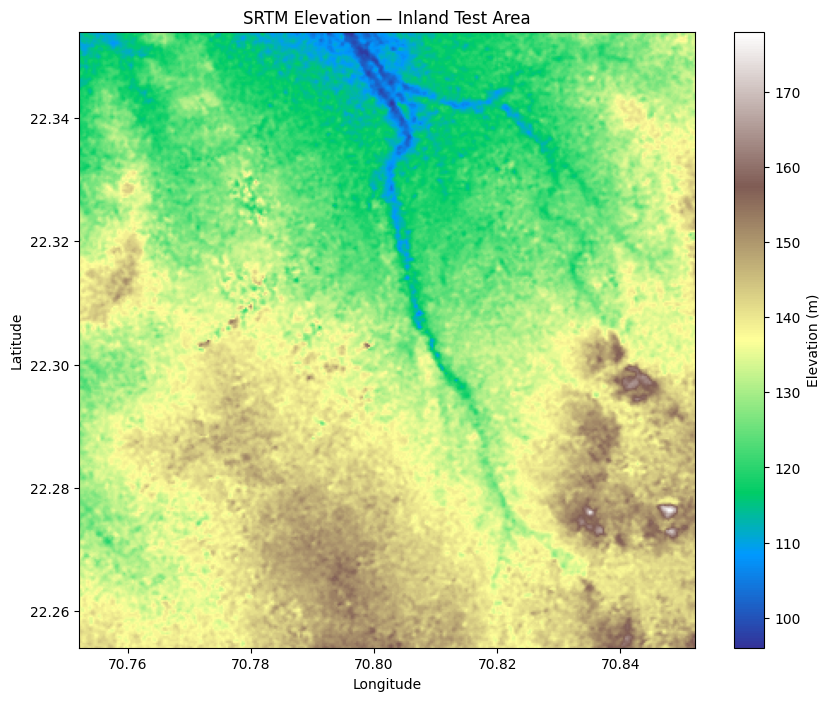

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.imshow(
    dem,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="terrain"
)

plt.colorbar(label="Elevation (m)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("SRTM Elevation — Inland Test Area")

plt.show()

In [ ]:
from rasterio.transform import xy

pixel_x = abs(transform.a)
pixel_y = abs(transform.e)

print("Longitude pixel size:", pixel_x)
print("Latitude pixel size :", pixel_y)

Longitude pixel size: 0.0002777777777777778
Latitude pixel size : 0.0002777777777777778


In [ ]:

# ============================================
# STEP 2.2 — CALCULATE TERRAIN SLOPE
# ============================================

# Convert the masked elevation raster to float
dem_values = dem.astype("float64").filled(np.nan)

# Latitude of each raster row (pixel centers)
row_indices = np.arange(dem.shape[0])

row_latitudes = (
    transform.f
    + (row_indices + 0.5) * transform.e
)

# Approximate pixel dimensions in metres
pixel_height_m = 110574 * abs(transform.e)

pixel_width_m = (
    111320
    * np.cos(np.deg2rad(row_latitudes))
    * abs(transform.a)
)

# Elevation gradients per pixel
dz_drow = np.gradient(dem_values, axis=0)
dz_dcol = np.gradient(dem_values, axis=1)

# Convert gradients to elevation change per metre
dz_dy = dz_drow / pixel_height_m
dz_dx = dz_dcol / pixel_width_m[:, None]

# Calculate slope in degrees
slope_deg = np.degrees(
    np.arctan(np.hypot(dz_dx, dz_dy))
)

# Mask cells where elevation is invalid
invalid = (
    np.ma.getmaskarray(dem)
    | ~np.isfinite(dem_values)
)

slope_deg[invalid] = np.nan

print("Slope calculation completed.")
print("Minimum slope:", np.nanmin(slope_deg))
print("Maximum slope:", np.nanmax(slope_deg))
print("Mean slope:", np.nanmean(slope_deg))


Slope calculation completed.
Minimum slope: 0.0
Maximum slope: 32.50637002971131
Mean slope: 2.664212163006877


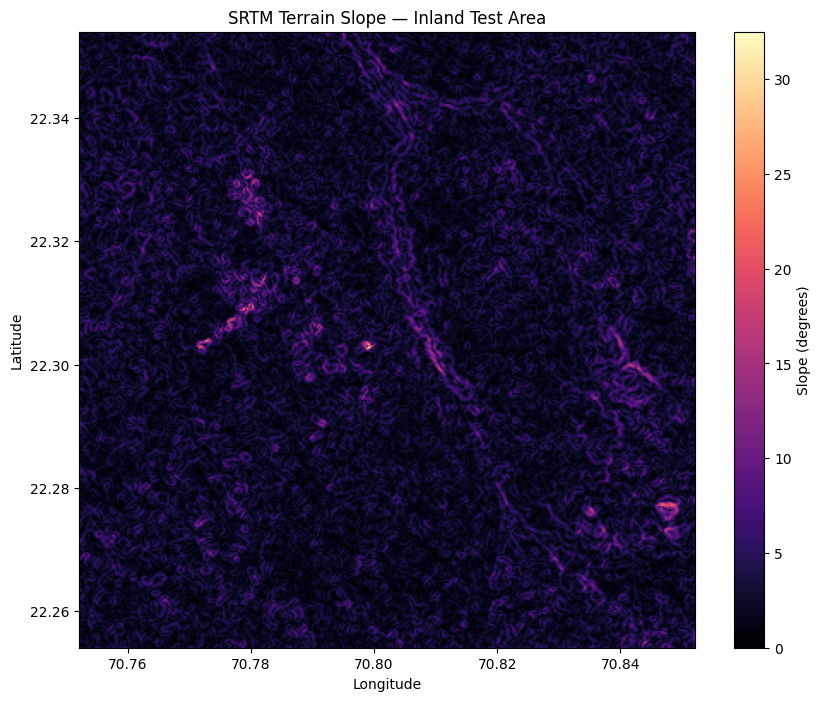

In [ ]:

plt.figure(figsize=(10, 8))

plt.imshow(
    slope_deg,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(label="Slope (degrees)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("SRTM Terrain Slope — Inland Test Area")

plt.show()


In [ ]:

from scipy.ndimage import uniform_filter

# ============================================
# STEP 2.3 — TERRAIN VARIABILITY
# ============================================

# Use a neighbourhood approximately 500 m wide
window_size = 17
half_window = window_size // 2

# Identify valid elevation pixels
valid_mask = np.isfinite(dem_values)

# Replace invalid cells temporarily for calculation
safe_dem = np.where(valid_mask, dem_values, 0.0)
valid_float = valid_mask.astype(float)

# Local proportion of valid pixels
valid_fraction = uniform_filter(
    valid_float,
    size=window_size,
    mode="constant",
    cval=0.0
)

# Avoid division by zero
valid_fraction = np.maximum(valid_fraction, 1e-12)

# Local mean elevation
local_mean = (
    uniform_filter(
        safe_dem,
        size=window_size,
        mode="constant",
        cval=0.0
    ) / valid_fraction
)

# Local mean squared elevation
local_mean_sq = (
    uniform_filter(
        safe_dem ** 2,
        size=window_size,
        mode="constant",
        cval=0.0
    ) / valid_fraction
)

# Local elevation variance and standard deviation
local_variance = np.maximum(
    local_mean_sq - local_mean ** 2,
    0.0
)

elevation_std_500m = np.sqrt(local_variance)

# Exclude invalid cells
elevation_std_500m[~valid_mask] = np.nan

# Exclude the raster edges where the full neighbourhood
# is not available
elevation_std_500m[:half_window, :] = np.nan
elevation_std_500m[-half_window:, :] = np.nan
elevation_std_500m[:, :half_window] = np.nan
elevation_std_500m[:, -half_window:] = np.nan

print("Terrain variability calculated.")
print("Minimum:", np.nanmin(elevation_std_500m), "m")
print("Maximum:", np.nanmax(elevation_std_500m), "m")
print("Mean:", np.nanmean(elevation_std_500m), "m")


Terrain variability calculated.
Minimum: 1.0485399706356462 m
Maximum: 10.228037743054152 m
Mean: 2.57237357483133 m


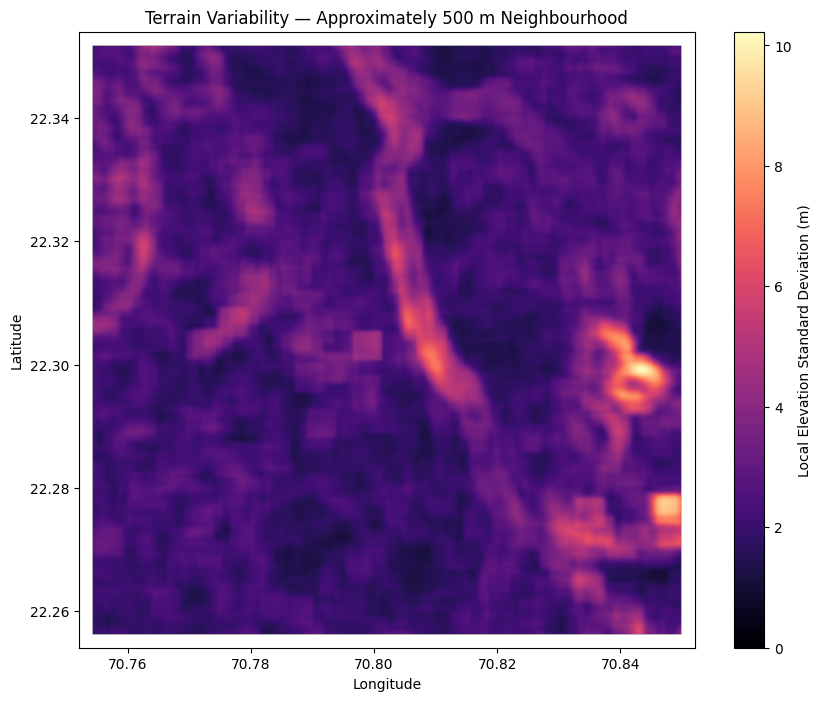

In [ ]:

plt.figure(figsize=(10, 8))

plt.imshow(
    elevation_std_500m,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="magma",
    vmin=0
)

plt.colorbar(
    label="Local Elevation Standard Deviation (m)"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Terrain Variability — Approximately 500 m Neighbourhood")

plt.show()


In [ ]:

# ============================================
# STEP 2.4 — LOAD NIWE POINTS IN THE TEST AREA
# ============================================

from pathlib import Path
import pandas as pd
import rasterio

NIWE_FILE = Path("N:\\Projects\\Wind_Energy_ML\\data\\raw\\150m_Map_Data_A_to_G.csv")
CHUNK_SIZE = 100_000

rename_map = {
    "Longitude (E)": "longitude",
    "Latitude (N)": "latitude",
    "Wind Speed (m/s)": "wind_speed",
    "Weibull A (m/s)": "weibull_a",
    "Weibull k": "weibull_k",
    "Air Density (kg/m3)": "air_density",
    "Wind Power Density (W/sq.m)": "wind_power_density"
}

if not NIWE_FILE.exists():
    raise FileNotFoundError(
        f"NIWE CSV not found: {NIWE_FILE}. "
        "Update NIWE_FILE to your actual file location."
    )

# Read bounds from the test DEM
with rasterio.open(test_dem) as src:
    bounds = src.bounds

print("DEM bounds:", bounds)

# Read the NIWE file in chunks and retain only
# the points inside the test DEM area.
local_parts = []

for chunk in pd.read_csv(
    NIWE_FILE,
    usecols=list(rename_map.keys()),
    chunksize=CHUNK_SIZE
):
    chunk = chunk.rename(columns=rename_map)

    inside = (
        chunk["longitude"].between(
            bounds.left, bounds.right
        )
        & chunk["latitude"].between(
            bounds.bottom, bounds.top
        )
    )

    if inside.any():
        local_parts.append(
            chunk.loc[inside].copy()
        )

if local_parts:
    niwe_local = pd.concat(
        local_parts,
        ignore_index=True
    )
else:
    niwe_local = pd.DataFrame(
        columns=list(rename_map.values())
    )

print("NIWE points inside test DEM:", len(niwe_local))
display(niwe_local.head())


FileNotFoundError: NIWE CSV not found: data/raw/150m_Map_Data_A_to_G.csv. Update NIWE_FILE to your actual file location.